# Chapitre 4 - Cours 4 : Concevoir un pipeline d'évaluation

Les benchmarks publics éliminent les mauvais modèles ; pour trouver le bon et guider le
développement dans la durée, il faut **son propre pipeline d'évaluation**. Ce notebook suit
la section *Design Your Evaluation Pipeline* du livre, centrée sur les tâches ouvertes :

1. vue d'ensemble du pipeline ;
2. étape 1 : évaluer chaque composant, par tour et par tâche (section *Step 1. Evaluate All Components in a System*) ;
3. étape 2 : lignes directrices, rubriques et métriques métier (section *Step 2. Create an Evaluation Guideline*) ;
4. étape 3 : choisir les méthodes, exploiter les logprobs (section *Select evaluation methods*) ;
5. découper par tranches et le paradoxe de Simpson (section *Annotate evaluation data*) ;
6. combien d'exemples ? bootstrap et taille d'échantillon ;
7. évaluer le pipeline d'évaluation (section *Evaluate your evaluation pipeline*) ;
8. itérer et tracer les expériences (section *Iterate*).

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.ticker import FuncFormatter
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.max_colwidth", 80)
llm.seed_everything(0)

## 1. Vue d'ensemble du pipeline (section *Design Your Evaluation Pipeline*)

Le succès d'une application d'IA tient souvent à sa capacité à **distinguer les bons
résultats des mauvais**. Le livre propose trois étapes, suivies d'une méta-évaluation et
d'une itération permanente. Le diagramme ci-dessous en donne la carte ; chaque section du
notebook en détaille une boîte.

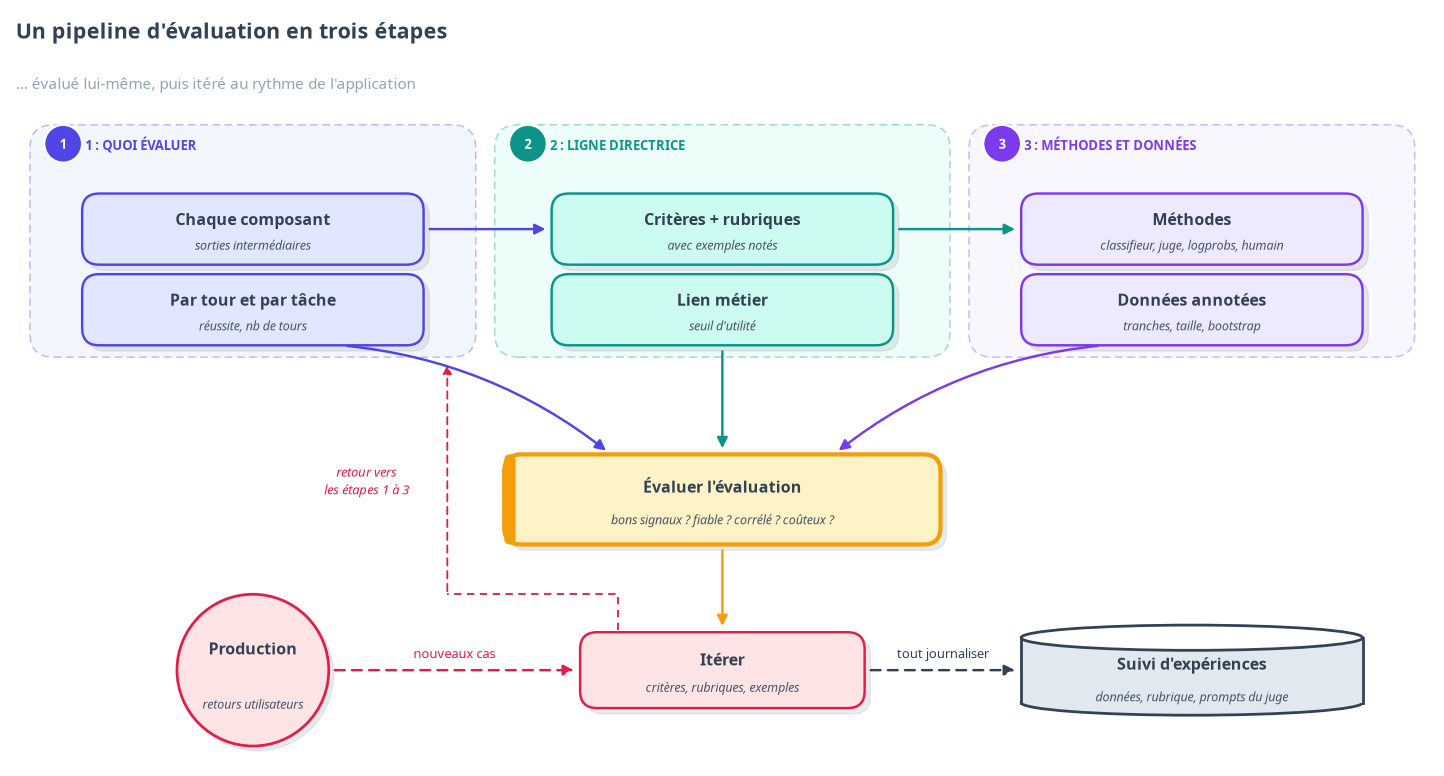

In [2]:
d = Diagram(15, 7.0, title="Un pipeline d'évaluation en trois étapes",
            subtitle="... évalué lui-même, puis itéré au rythme de l'application")
d.group(0.2, 4.3, 4.9, 6.75, "étape 1 : quoi évaluer", color=INDIGO)
d.group(5.1, 4.3, 9.9, 6.75, "étape 2 : ligne directrice", color=TEAL)
d.group(10.1, 4.3, 14.8, 6.75, "étape 3 : méthodes et données", color=VIOLET)
d.box("c1", 2.55, 5.65, "Chaque composant", sub="sorties intermédiaires", color=INDIGO, w=3.6, h=0.75)
d.box("c2", 2.55, 4.8, "Par tour et par tâche", sub="réussite, nb de tours", color=INDIGO, w=3.6, h=0.75)
d.box("g1", 7.5, 5.65, "Critères + rubriques", sub="avec exemples notés", color=TEAL, w=3.6, h=0.75)
d.box("g2", 7.5, 4.8, "Lien métier", sub="seuil d'utilité", color=TEAL, w=3.6, h=0.75)
d.box("m1", 12.45, 5.65, "Méthodes", sub="classifieur, juge, logprobs, humain", color=VIOLET, w=3.6, h=0.75)
d.box("m2", 12.45, 4.8, "Données annotées", sub="tranches, taille, bootstrap", color=VIOLET, w=3.6, h=0.75)
d.box("meta", 7.5, 2.8, "Évaluer l'évaluation", sub="bons signaux ? fiable ? corrélé ? coûteux ?", color=AMBER,
      w=4.6, h=0.95, kind="model")
d.box("prod", 2.55, 1.0, "Production", sub="retours utilisateurs", color=ROSE, kind="user", w=1.6)
d.box("log", 12.45, 1.0, "Suivi d'expériences", sub="données, rubrique, prompts du juge", color=SLATE, kind="db", w=3.6, h=0.95)
d.box("it", 7.5, 1.0, "Itérer", sub="critères, rubriques, exemples", color=ROSE, w=3.0, h=0.8)
d.arrow("c1", "g1", color=INDIGO); d.arrow("g1", "m1", color=TEAL)
d.arrow("g2", "meta", color=TEAL); d.arrow("m2", "meta", color=VIOLET, rad=0.15); d.arrow("c2", "meta", color=INDIGO, rad=-0.15)
d.arrow("meta", "it", color=AMBER)
d.arrow("it", "log", "tout journaliser", color=SLATE, style="dashed")
d.arrow("prod", "it", "nouveaux cas", color=ROSE, style="dashed")
d.line([(6.4, 1.42), (6.4, 1.8), (4.6, 1.8), (4.6, 4.25)], color=ROSE, style="dashed")
d.note(3.75, 3.0, "retour vers\nles étapes 1 à 3", color=ROSE, fontsize=8.5)
d.badge(0.55, 6.55, "1", INDIGO); d.badge(5.45, 6.55, "2", TEAL); d.badge(10.45, 6.55, "3", VIOLET)
d.show()

> **À retenir.** Un pipeline d'évaluation fiable répond à trois questions (quoi évaluer,
> qu'est-ce qu'une bonne réponse, avec quelles méthodes et quelles données), puis s'évalue
> lui-même et s'itère sous suivi d'expériences.

## 2. Étape 1 : évaluer chaque composant, par tour et par tâche (section *Step 1*)

**Évaluer chaque composant.** Reprenons l'exemple du livre : extraire l'employeur actuel
d'une personne à partir de son CV en PDF, en deux étapes : (1) PDF vers texte ; (2) extraction
de l'employeur depuis le texte. Si la sortie finale est fausse, laquelle des deux étapes a
échoué ? Sans évaluation par composant, impossible de le savoir. On évalue :

- l'étape 1 par la **similarité** entre le texte extrait et le texte de référence ;
- l'étape 2 par l'**exactitude** *sachant un texte correct* ;
- le système complet de bout en bout.

On simule l'étape 1 par une extraction bruitée (caractères confondus comme `l`/`1` ou
`e`/`c`, espaces perdues) à différents taux d'erreur, et l'étape 2 est confiée à Qwen 0.5B.

In [3]:
cvs = c4.make_resumes(16, seed=0)
print(cvs[0]["texte"]); print("-> employeur attendu :", cvs[0]["employeur"])
print("\nAvec 8 % de bruit d'extraction :\n" + c4.ocr_noise(cvs[0]["texte"], 0.08, seed=0)[:220], "...")

Claire Benali
Courriel : claire@exemple.fr

EXPÉRIENCE PROFESSIONNELLE
- 2008 - 2010 : chef de projet chez Sanofi
- depuis 2012 (poste actuel) : développeur web chez Alstom
- 2010 - 2012 : consultant chez Thales

FORMATION
- Master obtenu en 2007

LANGUES : français, anglais
-> employeur attendu : Alstom

Avec 8 % de bruit d'extraction :
Clolre Bena1i
Courricl : claire@exemple.fr

EXPÉRIENCE PROFESSIONNELLE
- 2008 - 2010 : chef de projet chez Sonofi
- dcpvis 2012 (poste actuel) : dével0ppeur web chez Alstom
- 2010 - 2012 : consultont chez Tholes

FORMATI ...


In [4]:
q = ("Voici un CV.\n\n{cv}\n\nQuel est l'employeur actuel de cette personne ? "
     "Réponds uniquement par le nom de l'entreprise.")
rates = [0.0, 0.03, 0.08, 0.15, 0.25]
rows = []
for r in rates:
    texts = [c4.ocr_noise(cv["texte"], r, seed=i) for i, cv in enumerate(cvs)]
    preds = c4.chat_batch([q.format(cv=t) for t in texts], llm.SMALL, max_new_tokens=12)
    for cv, t, p in zip(cvs, texts, preds):
        rows.append(dict(bruit=r, sim=c4.text_similarity(t, cv["texte"]),
                         ok=c4.answer_match(p, cv["employeur"]), pred=p))
comp = pd.DataFrame(rows)
etape2 = comp[comp.bruit == 0].ok.mean()                 # étape 2 seule, sur texte parfait
agg = comp.groupby("bruit").agg(similarite_etape1=("sim", "mean"), exactitude_bout_en_bout=("ok", "mean"))
agg["exactitude_etape2_isolee"] = etape2
agg.round(3)

,similarite_etape1,exactitude_bout_en_bout,exactitude_etape2_isolee
bruit,,,
0.00,1.000,0.875,0.875
0.03,0.957,0.688,0.875
0.08,0.885,0.312,0.875
0.15,0.798,0.188,0.875
0.25,0.686,0.250,0.875


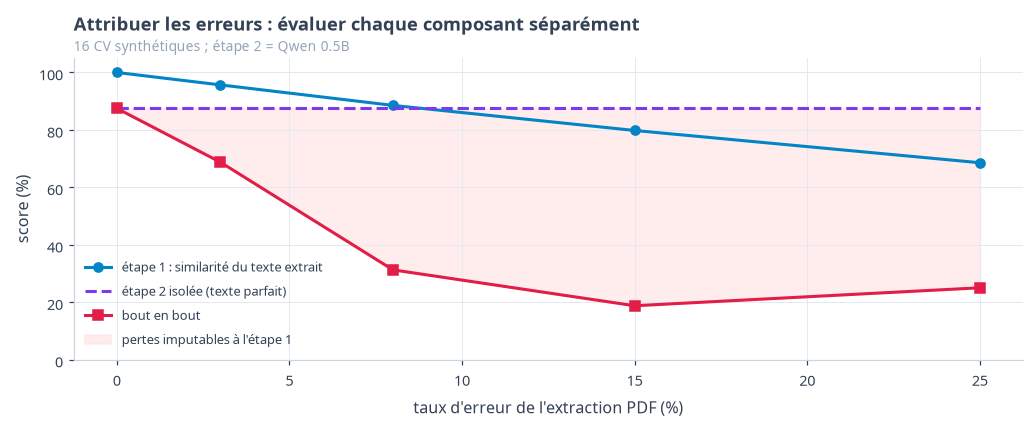

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.array(rates) * 100
ax.plot(x, agg.similarite_etape1 * 100, "o-", color=SKY, label="étape 1 : similarité du texte extrait")
ax.plot(x, agg.exactitude_etape2_isolee * 100, "--", color=VIOLET, label="étape 2 isolée (texte parfait)")
ax.plot(x, agg.exactitude_bout_en_bout * 100, "s-", color=ROSE, label="bout en bout")
ax.fill_between(x, agg.exactitude_bout_en_bout * 100, agg.exactitude_etape2_isolee * 100, color=LIGHT[ROSE],
                alpha=0.7, label="pertes imputables à l'étape 1")
ax.set_xlabel("taux d'erreur de l'extraction PDF (%)"); ax.set_ylabel("score (%)"); ax.set_ylim(0, 105)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Attribuer les erreurs : évaluer chaque composant séparément", pad=18)
subtitle(ax, f"{len(cvs)} CV synthétiques ; étape 2 = Qwen 0.5B")
plt.tight_layout(); plt.show()

L'écart entre l'étape 2 isolée et le bout en bout est imputable à l'extraction : si l'étape 2
isolée est déjà médiocre, inutile d'améliorer l'OCR en premier ; si elle est bonne mais que
le bout en bout s'effondre avec le bruit, c'est l'extraction qu'il faut soigner. Avec un modèle
de 0,5 milliard de paramètres, l'étape 2 n'est pas parfaite même sur texte propre : il
confond parfois un ancien employeur et l'actuel (lire « depuis ... (poste actuel) » demande
un peu de raisonnement).

**Par tour et par tâche.** Un **tour** peut contenir plusieurs étapes ; une **tâche** peut
demander plusieurs tours (le modèle demande la version de Python avant de déboguer). L'évaluation
par tâche est la plus importante (l'utilisateur veut que sa tâche aboutisse) et compte aussi le
**nombre de tours** : résoudre en 2 tours ou en 20 change tout. Le livre cite le benchmark
*twenty_questions* de BIG-bench : un joueur pense à un objet, l'autre doit le deviner par des
questions oui/non. Simulons deux questionneurs sur 16 objets décrits par 10 attributs.

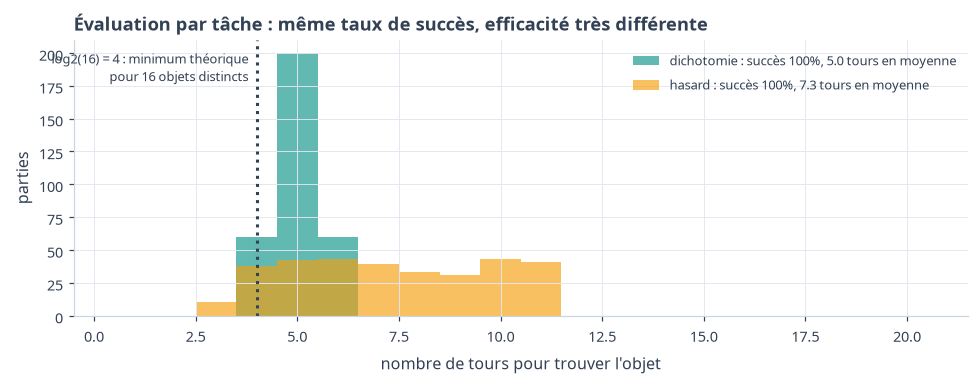

In [6]:
games = []
for strat in ["dichotomie", "hasard"]:
    for seed in range(20):
        for obj in c4.TWENTY_Q_OBJECTS:
            ok, turns = c4.play_twenty_questions(obj, strat, seed=seed)
            games.append(dict(stratégie=strat, objet=obj, succès=ok, tours=turns))
games = pd.DataFrame(games)
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(1, 22) - 0.5
for strat, c in [("dichotomie", TEAL), ("hasard", AMBER)]:
    g = games[games.stratégie == strat]
    ax.hist(g.tours, bins=bins, color=c, alpha=0.65, label=f"{strat} : succès {g.succès.mean():.0%}, "
            f"{g.tours.mean():.1f} tours en moyenne")
ax.axvline(np.log2(16), color=SLATE, ls=":")
ax.text(np.log2(16) - 0.2, ax.get_ylim()[1] * 0.85, "log2(16) = 4 : minimum théorique\npour 16 objets distincts",
        fontsize=8.5, ha="right")
ax.set_xlabel("nombre de tours pour trouver l'objet"); ax.set_ylabel("parties")
ax.set_title("Évaluation par tâche : même taux de succès, efficacité très différente"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Les deux questionneurs finissent par trouver (succès identique), mais la dichotomie y arrive
en moins de tours et avec une dispersion bien plus faible (le hasard pose souvent des
questions inutiles) : une métrique de succès seule masquerait cette différence. Notez
que certains objets partagent tous leurs attributs (pomme, fraise et carotte sont ici
indiscernables) : il faut alors deviner, ce qui ajoute des tours, même avec la meilleure
stratégie. La difficulté pratique de l'évaluation par tâche est ailleurs : dans une vraie
conversation, où s'arrête une tâche et où commence la suivante ?

> **À retenir.** Évaluez chaque composant séparément (sinon vous ne savez pas où le système
> échoue), et le système entier par tâche, en comptant les tours, pas seulement le succès.

## 3. Étape 2 : lignes directrices, rubriques, métriques métier (section *Step 2*)

C'est **l'étape la plus importante** selon le livre : une ligne directrice ambiguë produit
des scores ambigus. Elle définit ce que l'application doit faire **et ce qu'elle ne doit pas
faire** (un chatbot de support doit-il parler des élections ?). LinkedIn rapporte que la
première difficulté a été de définir une bonne réponse : « vous ne correspondez pas du tout
au poste » peut être correct, mais n'est pas utile.

**Critères.** Pour un support client, par exemple : pertinence, cohérence factuelle,
sécurité (les utilisateurs de LangChain combinent en moyenne 2,3 types de retour). **Rubrique.**
Pour chaque critère, un système de notation (binaire, -1/0/1, 1 à 5...) et des **exemples
notés** qui justifient chaque note, validés par plusieurs humains : si eux-mêmes ne sont pas
d'accord, la rubrique est à reprendre.

In [7]:
rubrique = pd.DataFrame([
    (-1, "contradiction", "Au moins une affirmation contredit le contexte.",
     "« La médiathèque est ouverte le dimanche. »"),
    (0, "neutre", "Aucune contradiction, mais des affirmations invérifiables dans le contexte.",
     "« La médiathèque possède un café. »"),
    (1, "implication", "Toutes les affirmations se déduisent du contexte.",
     "« Les mineurs s'inscrivent gratuitement. »"),
], columns=["note", "étiquette", "définition", "exemple (contexte : fiche de la médiathèque)"])
rubrique

,note,étiquette,définition,exemple (contexte : fiche de la médiathèque)
0,-1,contradiction,Au moins une affirmation contredit le contexte.,« La médiathèque est ouverte le dimanche. »
1,0,neutre,"Aucune contradiction, mais des affirmations invérifiables dans le contexte.",« La médiathèque possède un café. »
2,1,implication,Toutes les affirmations se déduisent du contexte.,« Les mineurs s'inscrivent gratuitement. »


**Relier aux métriques métier.** Que signifie une cohérence factuelle de 80 % pour
l'entreprise ? Le livre propose de construire une correspondance entre métrique d'évaluation
et métrique métier (ici, la part des demandes de support automatisables), et d'en déduire un
**seuil d'utilité** en dessous duquel l'application est inutilisable.

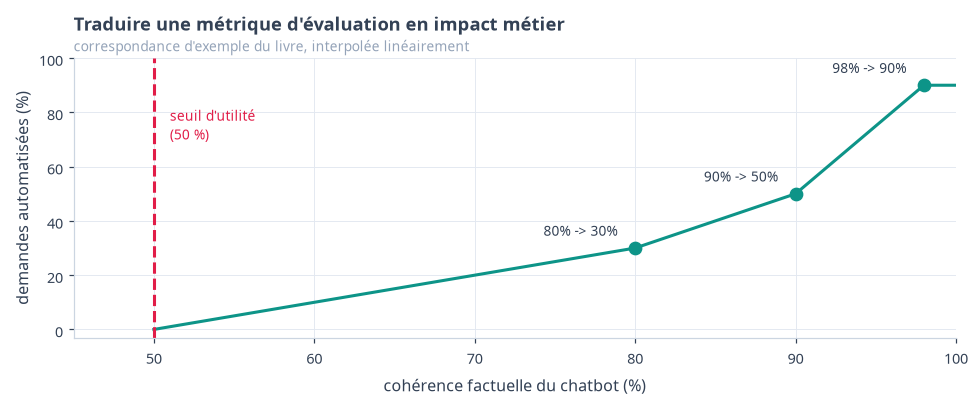

In [8]:
fc = np.array([0.5, 0.8, 0.9, 0.98])
auto = np.array([0.0, 0.30, 0.50, 0.90])
xs = np.linspace(0.5, 1.0, 200)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xs * 100, np.interp(xs, fc, auto) * 100, color=TEAL)
ax.plot(fc[1:] * 100, auto[1:] * 100, "o", color=TEAL, ms=8)
for f, a in zip(fc[1:], auto[1:]):
    ax.annotate(f"{f:.0%} -> {a:.0%}", (f * 100, a * 100), xytext=(-60, 8), textcoords="offset points", fontsize=9)
ax.axvline(50, color=ROSE, ls="--"); ax.text(51, 70, "seuil d'utilité\n(50 %)", color=ROSE, fontsize=9)
ax.set_xlabel("cohérence factuelle du chatbot (%)"); ax.set_ylabel("demandes automatisées (%)")
ax.set_xlim(45, 100); ax.set_ylim(-3, 100)
ax.set_title("Traduire une métrique d'évaluation en impact métier", pad=18)
subtitle(ax, "correspondance d'exemple du livre, interpolée linéairement")
plt.tight_layout(); plt.show()

La courbe est convexe : les derniers points de cohérence factuelle valent beaucoup plus que
les premiers (passer de 90 à 98 % fait passer l'automatisation de 50 à 90 %). Cette
correspondance permet de **chiffrer l'intérêt** d'un investissement d'amélioration. Le livre
invite aussi à réfléchir aux métriques métier visées (utilisateurs actifs, engagement) et à
leurs effets pervers (fonctionnalités addictives).

> **À retenir.** Une bonne ligne directrice définit les critères, une rubrique avec exemples
> validée par des humains, et une correspondance avec les métriques métier assortie d'un seuil
> d'utilité.